# PHO Infectious Disease Surveillance Analysis
## 02 | Exploratory Data Analysis & Epidemiological Visualizations

**Source:** Public Health Ontario (PHO) · **Period:** 2016–2025  
**Audience:** Public-health analysts, healthcare analytics teams, portfolio reviewers  
**Stack:** pandas · NumPy · Plotly · Jupyter Notebook

### Research questions
1. Which reportable diseases generate the greatest number of reported cases in Ontario?
2. How have selected disease counts changed over time?
3. How does a selected disease's **reported rate** vary across local public health units (PHUs)?
4. How are case counts distributed across age and sex groups?
5. What do the available hospitalization and death outcome percentages show?
6. Which diseases saw the largest **absolute** year-over-year changes?

### Analytical rules
- **Geographic levels must not be added together.** `Ontario` is a provincial summary; PHUs are components of Ontario, and `Canada` is a separate higher-level row in this export.
- Disease **case counts** are not equivalent to incidence rates, and different diseases can have different population denominators and surveillance definitions.
- `0` (zero cases), a missing observation, and a missing rate (including zero or unavailable population) are different states.
- Demographic counts are descriptive and **not population-adjusted risk estimates**. Show only one disease/year/geographic grain at a time for age distributions.
- Default **reference year: 2024** for stable comparisons; 2025 is displayed in time series but should be checked against PHO release notes for completeness/revisions.
- Outcome percentages are **reported proportions among the disease's recorded cases**, not population mortality or hospitalization rates.

The notebook is **standalone**: it reloads raw files instead of depending on variables from Notebook 01. It does not modify the source Excel workbooks.

---

**Local setup (VS Code terminal):** `python -m pip install pandas numpy plotly openpyxl ipykernel`  
**Optional static chart exports:** `python -m pip install kaleido` (may also need Chrome).


### 01 | Configuration & Data Loading

**Inputs:** the same three PHO Excel exports used in `01_data_quality.ipynb`. The notebook is located in `notebooks/`, next to the project-level `data/` and `outputs/` directories. Set chart parameters here; the rest of the notebook adapts automatically.

In [1]:
# ============================================================
# 01A | Dependencies, Parameters & Paths
# ============================================================
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

warnings.filterwarnings("ignore", message="Workbook contains no default style", category=UserWarning)
pd.set_option("display.max_rows", 15)
pd.set_option("display.max_columns", 12)

# User-adjustable analysis parameters
REFERENCE_YEAR = 2024
GEO_DISEASE = "Lyme Disease"
AGE_DISEASE = "Lyme Disease"
SEX_DISEASES = ["Lyme Disease", "Salmonellosis", "Syphilis, Infectious", "Campylobacter Enteritis"]
OUTCOME_DISEASE = "Salmonellosis"
MAX_PHUS_IN_HEATMAP = 15
MIN_BASELINE_CASES_FOR_YOY = 50

# Output controls. HTML files open in a browser; PNG needs the optional 'kaleido' package.
EXPORT_DASHBOARD_TABLES = True
SAVE_CHART_HTML = False
SAVE_CHART_PNG = False

PROJECT_ROOT = next(
    (p.resolve() for p in [Path.cwd(), Path.cwd().parent] if (p / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from the project root or notebooks/; sibling data/ must exist.")
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
CHART_DIR = OUTPUT_DIR / "figures"

files = {
    "Overall": DATA_DIR / "Overall.xlsx",
    "Age & Sex": DATA_DIR / "by_sex_age.xlsx",
    "Outcome": DATA_DIR / "outcome.xlsx",
}
for label, path in files.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {label}: {path}")
print("PHO EDA environment ready | reference year:", REFERENCE_YEAR)

PHO EDA environment ready | reference year: 2024


In [2]:
# ------------------------------------------------------------
# 01B | Read Source Exports & Confirm Structure
# ------------------------------------------------------------
raw_overall = pd.read_excel(files["Overall"])
raw_age = pd.read_excel(files["Age & Sex"])
raw_outcome = pd.read_excel(files["Outcome"])

required = {
    "Overall": (raw_overall, {"Public health unit", "Disease", "Time period", "Time unit", "Cases", "Population", "Rate per 100,000"}),
    "Age & Sex": (raw_age, {"Public health unit", "Disease", "Year", "Sex", "Age group", "Number of cases", "Population"}),
    "Outcome": (raw_outcome, {"Public health unit", "Disease", "Outcome", "Year", "Cases with outcome", "Total cases", "Percent of cases with outcome"}),
}
for name, (frame, expected) in required.items():
    missing = expected.difference(frame.columns)
    if missing:
        raise ValueError(f"{name}: missing expected columns {sorted(missing)}")

display(pd.DataFrame([
    {"Dataset": name, "Records": len(frame), "Columns": frame.shape[1]}
    for name, (frame, _) in required.items()
]))

,Dataset,Records,Columns
0,Overall,20034,7
1,Age & Sex,213741,8
2,Outcome,650,7


### 02 | Analysis-Ready Tables & Reporting Guardrails

Build minimal working copies, remove the two known non-data footer records in the Outcome export, and explicitly separate Ontario, PHUs, and Canada. This step does **not** impute missing rates or force disagreeing subtotals to match.

In [3]:
# ============================================================
# 02 | Prepare & Separate Reporting Grains
# ============================================================
overall = raw_overall.copy()
age = raw_age.copy()
outcome = raw_outcome.copy()

for df in (overall, age, outcome):
    for col in ("Public health unit", "Disease"):
        df[col] = df[col].astype("string").str.strip()

overall["Year"] = pd.to_numeric(overall["Time period"], errors="coerce").astype("Int64")
age["Year"] = pd.to_numeric(age["Year"], errors="coerce").astype("Int64")

# Keep only annual observations for comparisons between years.
overall = overall.loc[overall["Time unit"].astype("string").str.strip().eq("Years")].copy()

# Remove Outcome blank/export-metadata records and standardize its year.
outcome = outcome.loc[
    outcome[["Disease", "Outcome", "Year", "Cases with outcome", "Total cases"]]
    .notna().all(axis=1)
].copy()
outcome["Year"] = pd.to_numeric(outcome["Year"], errors="raise").astype(int)
outcome["Outcome"] = outcome["Outcome"].astype("string").str.strip()

province = overall.loc[overall["Public health unit"].eq("Ontario")].copy()
phu = overall.loc[~overall["Public health unit"].isin(["Ontario", "Canada"])].copy()
age_province = age.loc[age["Public health unit"].eq("Ontario")].copy()
outcome_province = outcome.loc[outcome["Public health unit"].eq("Ontario")].copy()

if province.empty or phu.empty:
    raise ValueError("Expected Ontario and PHU observations were not found; review geographic labels.")
if REFERENCE_YEAR not in province["Year"].values:
    raise ValueError(f"Reference year {REFERENCE_YEAR} is not in the Ontario dataset.")

scope = pd.DataFrame([
    {"Analysis table": "Ontario summary", "Records": len(province), "Geographies": 1},
    {"Analysis table": "PHU observations", "Records": len(phu), "Geographies": phu["Public health unit"].nunique()},
    {"Analysis table": "Age & Sex | Ontario", "Records": len(age_province), "Geographies": 1},
    {"Analysis table": "Outcome | Ontario", "Records": len(outcome_province), "Geographies": 1},
])
display(scope)

,Analysis table,Records,Geographies
0,Ontario summary,630,1
1,PHU observations,18734,29
2,Age & Sex | Ontario,7860,1
3,Outcome | Ontario,648,1


### 03 | Consistent Visualization Design

All seven charts share an accessible, presentation-ready visual system: typography, semantic color usage, clear units, restrained grid lines, and informative tooltips. Charts are interactive in Jupyter; optional HTML/PNG exports can be enabled in Section 01. **GitHub does not consistently render interactive Plotly notebook output**, so use static PNG previews in the README or the eventual Streamlit deployment.

In [4]:
# ============================================================
# 03 | Visualization Helpers
# ============================================================
NAVY = "#17233B"
MUTED = "#65758B"
GRID = "#E8EDF4"
BLUE = "#2563EB"
TEAL = "#0D9488"
CORAL = "#EA580C"
VIOLET = "#7C3AED"
PALETTE = [BLUE, TEAL, VIOLET, CORAL, "#0EA5E9", "#D946EF"]


def finish_chart(fig, title, subtitle, height=510, left_margin=90):
    """Apply a consistent, high-legibility healthcare analytics chart theme."""
    fig.update_layout(
        title={"text": f"{title}<br><span style='font-size:12px;color:{MUTED}'>{subtitle}</span>",
               "x": 0.02, "xanchor": "left", "font": {"size": 20, "color": NAVY}},
        font={"family": "Arial, sans-serif", "size": 12, "color": NAVY},
        template="plotly_white", paper_bgcolor="#FFFFFF", plot_bgcolor="#FFFFFF",
        margin={"l": left_margin, "r": 42, "t": 95, "b": 70}, height=height,
        hoverlabel={"bgcolor": NAVY, "font": {"color": "white", "size": 12}},
        legend={"title": {"text": ""}, "orientation": "h", "y": -0.19, "x": 0},
    )
    fig.update_xaxes(showline=False, showgrid=False, zeroline=False, ticks="")
    fig.update_yaxes(showline=False, gridcolor=GRID, zeroline=False, ticks="")
    return fig


def show_chart(fig, slug):
    """Render the chart and optionally save a portable copy."""
    fig.show()
    if SAVE_CHART_HTML or SAVE_CHART_PNG:
        CHART_DIR.mkdir(parents=True, exist_ok=True)
    if SAVE_CHART_HTML:
        fig.write_html(CHART_DIR / f"{slug}.html", include_plotlyjs="cdn")
    if SAVE_CHART_PNG:
        try:
            fig.write_image(CHART_DIR / f"{slug}.png", scale=2, width=1200)
        except Exception as exc:
            print(f"PNG export skipped ({slug}): install/configure kaleido. {exc}")


# All disease-wide year-by-year comparisons use the province-only table.
province_year = province.groupby(["Disease", "Year"], as_index=False, dropna=False)["Cases"].sum()
print(f"Plotly theme ready | {province['Disease'].nunique()} diseases | {phu['Public health unit'].nunique()} PHUs")

Plotly theme ready | 67 diseases | 29 PHUs


### 04 | Disease Burden: Top 10 Reported Case Counts

**Question:** Which diseases accounted for the most reported Ontario cases in the reference year?  
**Metric:** absolute number of reported cases (not an adjusted incidence or severity ranking).  
**Why this chart:** A horizontal bar chart makes long disease names readable and reveals the scale difference without relying on a crowded legend.

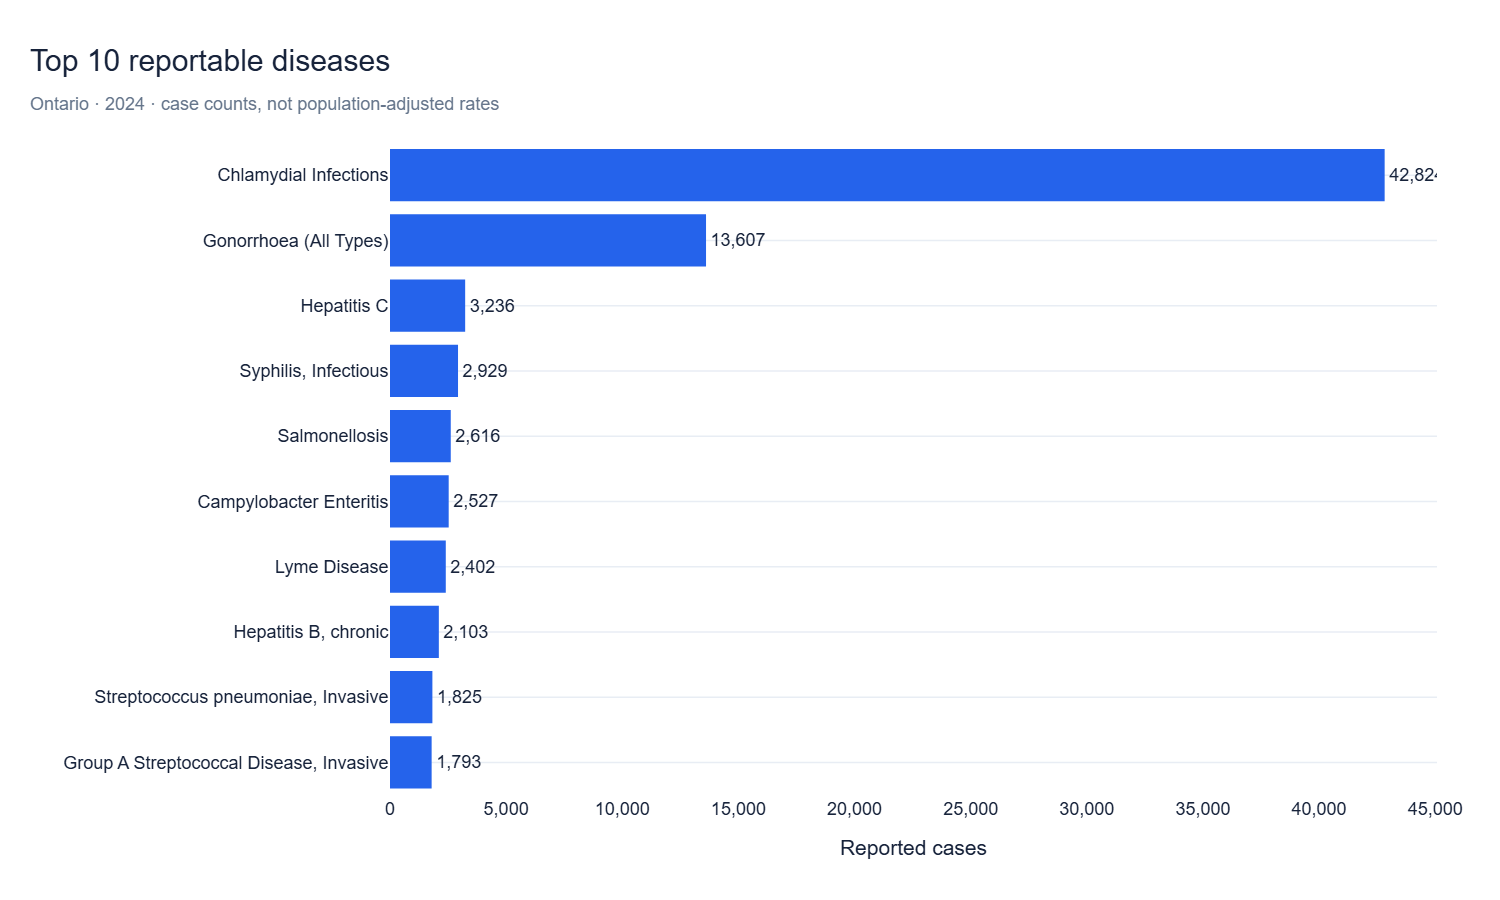

Most reported: Chlamydial Infections (42,824 cases)


In [5]:
# ============================================================
# 04 | Chart 1 — Top 10 Diseases
# ============================================================
top10 = (province_year.loc[province_year["Year"].eq(REFERENCE_YEAR)]
         .nlargest(10, "Cases").sort_values("Cases"))

fig = px.bar(
    top10, x="Cases", y="Disease", orientation="h", text="Cases",
    color_discrete_sequence=[BLUE],
)
fig.update_traces(
    marker_line_width=0, texttemplate="%{x:,.0f}", textposition="outside",
    hovertemplate="<b>%{y}</b><br>Reported cases: %{x:,.0f}<extra></extra>",
)
fig.update_xaxes(title="Reported cases", tickformat=",")
fig.update_yaxes(title=None, gridcolor="white")
fig = finish_chart(fig, "Top 10 reportable diseases", f"Ontario · {REFERENCE_YEAR} · case counts, not population-adjusted rates", height=570, left_margin=260)
fig.update_layout(showlegend=False)
show_chart(fig, "01_top_10_diseases")
print("Most reported:", top10.iloc[-1]["Disease"], f"({top10.iloc[-1]['Cases']:,.0f} cases)")

### 05 | Ten-Year Trends for Selected Diseases

**Question:** How have the five highest-count diseases in the reference year evolved from 2016 to 2025?  
**Metric:** annual Ontario cases, with missing combinations left missing rather than invented as zeros.  
**Interpretation:** A trend reflects reported cases and may be influenced by testing, reporting, case definitions, healthcare access, and true transmission.

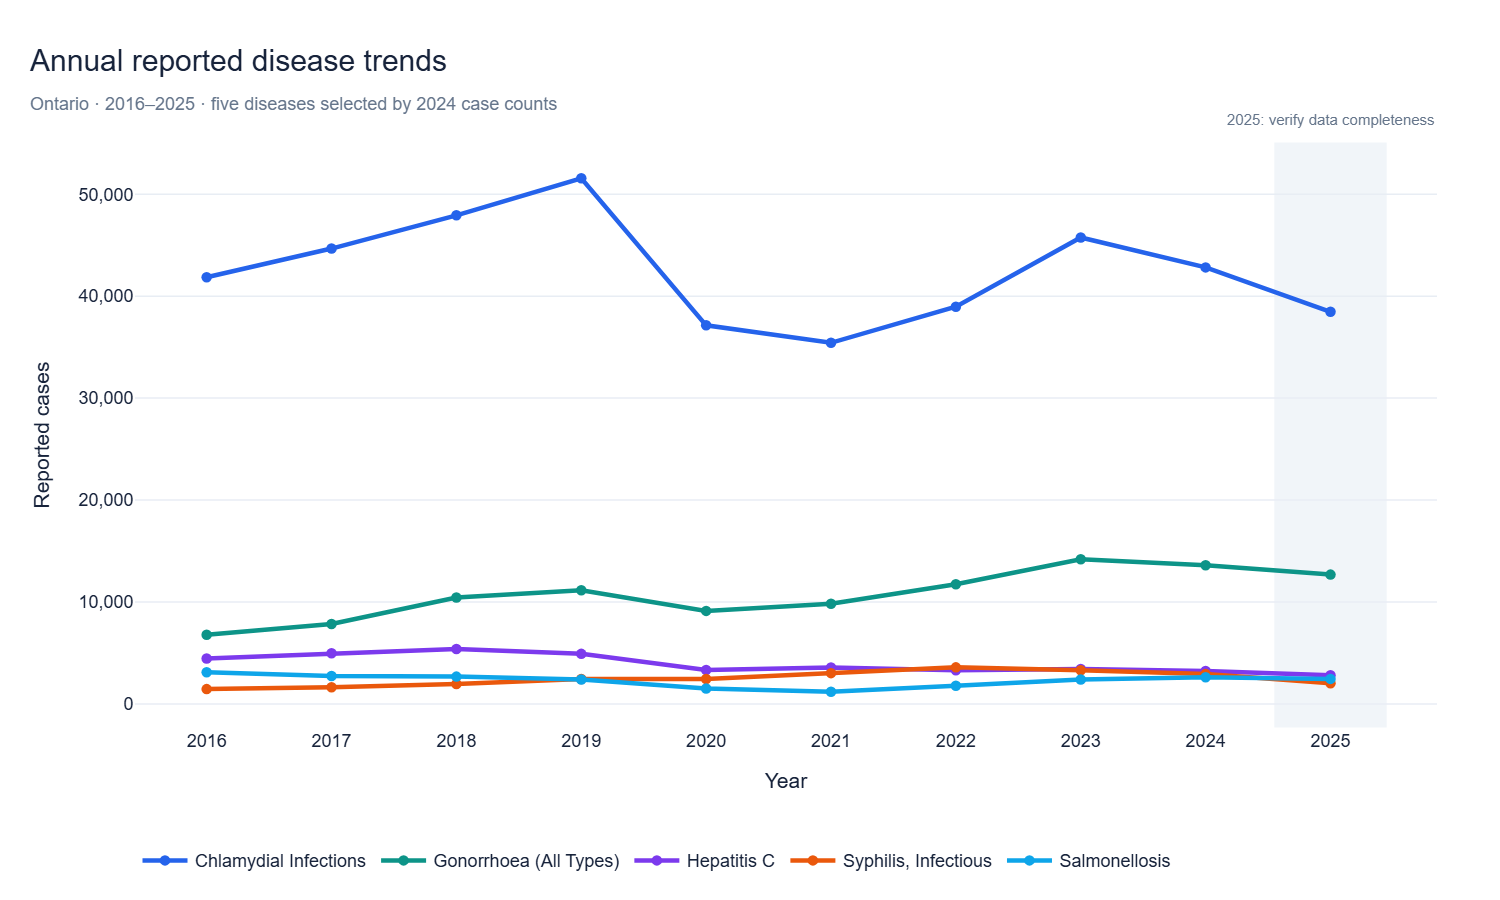

In [6]:
# ============================================================
# 05 | Chart 2 — Ontario Disease Trends
# ============================================================
top5_names = (province_year.loc[province_year["Year"].eq(REFERENCE_YEAR)]
              .nlargest(5, "Cases")["Disease"].tolist())
years = sorted(province_year["Year"].dropna().astype(int).unique().tolist())

# Insert explicit missing rows so lines do not imply absent annual observations were zero.
trend = (province_year.loc[province_year["Disease"].isin(top5_names)]
         .set_index(["Disease", "Year"])
         .reindex(pd.MultiIndex.from_product([top5_names, years], names=["Disease", "Year"]))
         .reset_index())
fig = px.line(
    trend, x="Year", y="Cases", color="Disease", markers=True,
    color_discrete_sequence=PALETTE, category_orders={"Disease": top5_names},
)
fig.update_traces(line={"width": 3}, marker={"size": 7}, connectgaps=False,
    hovertemplate="%{fullData.name}<br>%{x}: %{y:,.0f} cases<extra></extra>")
fig.update_xaxes(title="Year", dtick=1, tickmode="linear")
fig.update_yaxes(title="Reported cases", tickformat=",")
fig = finish_chart(fig, "Annual reported disease trends", "Ontario · 2016–2025 · five diseases selected by 2024 case counts", height=560)
if 2025 in years:
    fig.add_vrect(x0=2024.55, x1=2025.45, fillcolor="#F1F5F9", line_width=0, layer="below")
    fig.add_annotation(x=2025, y=1.06, yref="paper", text="2025: verify data completeness", showarrow=False,
                       font={"size": 10, "color": MUTED})
show_chart(fig, "02_annual_disease_trends")

### 06 | Geographic Variation: PHU × Year Rate Heatmap

**Question:** Where and when have high reported rates occurred for one selected disease?  
**Metric:** PHO's **reported rate per 100,000** for the same disease at the local PHU level. `Ontario` and `Canada` summary rows are intentionally excluded.  
**Display:** Up to 15 PHUs ordered by their average **available** rate; this is a focused comparison, **not** a map or an all-PHU ranking. Missing rates remain blank (not zero).

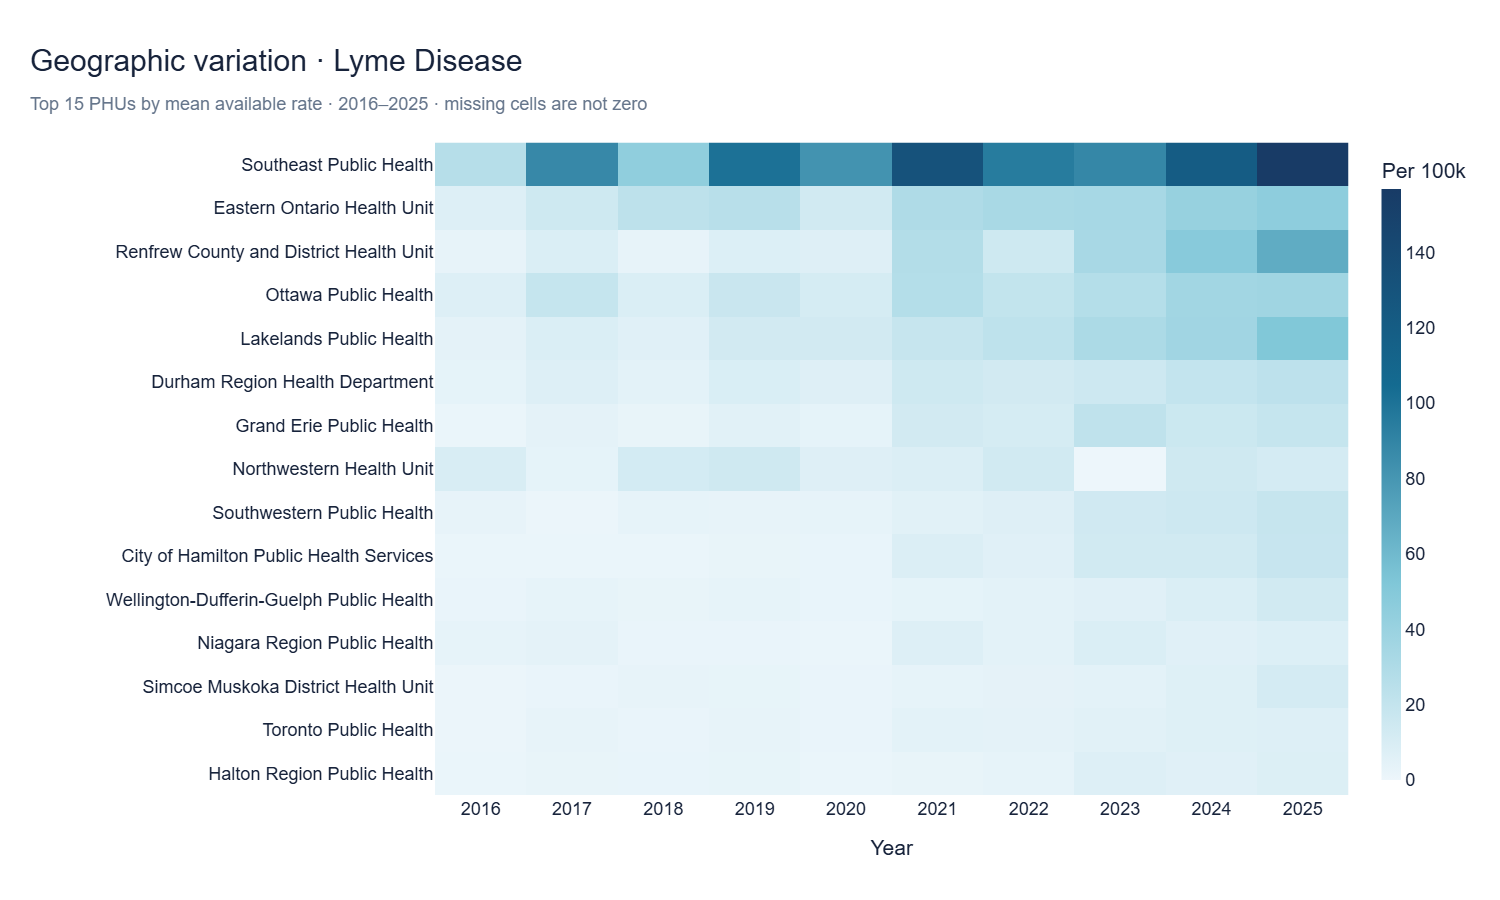

In [7]:
# ============================================================
# 06 | Chart 3 — PHU-Year Rate Heatmap
# ============================================================
if GEO_DISEASE not in phu["Disease"].values:
    raise ValueError(f"Unknown GEO_DISEASE: {GEO_DISEASE}")

g = phu.loc[phu["Disease"].eq(GEO_DISEASE),
            ["Public health unit", "Year", "Rate per 100,000"]].copy()
g["Rate per 100,000"] = pd.to_numeric(g["Rate per 100,000"], errors="coerce")
phu_order = (g.groupby("Public health unit")["Rate per 100,000"]
             .mean().dropna().nlargest(MAX_PHUS_IN_HEATMAP).index.tolist())
heat = (g.loc[g["Public health unit"].isin(phu_order)]
        .pivot(index="Public health unit", columns="Year", values="Rate per 100,000")
        .reindex(index=phu_order, columns=years))
if heat.empty or heat.notna().sum().sum() == 0:
    raise ValueError("Selected disease has no comparable PHU rate observations.")

fig = px.imshow(
    heat, aspect="auto", color_continuous_scale=["#EDF6FB", "#80C7D8", "#146B91", "#183B66"],
    labels={"color": "Rate / 100k", "x": "Year", "y": "Public health unit"},
)
fig.update_traces(hovertemplate="<b>%{y}</b><br>Year: %{x}<br>Rate: %{z:.2f} per 100,000<extra></extra>")
fig.update_xaxes(title="Year", type="category")
fig.update_yaxes(title=None, showgrid=False, autorange="reversed")
fig = finish_chart(fig, f"Geographic variation · {GEO_DISEASE}",
                   f"Top {len(phu_order)} PHUs by mean available rate · 2016–2025 · missing cells are not zero",
                   height=680, left_margin=290)
fig.update_layout(coloraxis_colorbar={"title": "Per 100k", "thickness": 13})
show_chart(fig, "03_phu_rate_heatmap")

### 07 | Age Distribution of Reported Cases

**Question:** How are cases for one disease distributed among its **reported** age strata in 2024?  
**Metric:** number of cases (not age-adjusted incidence).  
**Guardrail:** PHO uses disease-specific age bands, so **do not pool age labels across diseases**. A simple age-band overlap screen is applied before aggregating across sex. Unknown age may be shown as an additional, nonnumeric category.

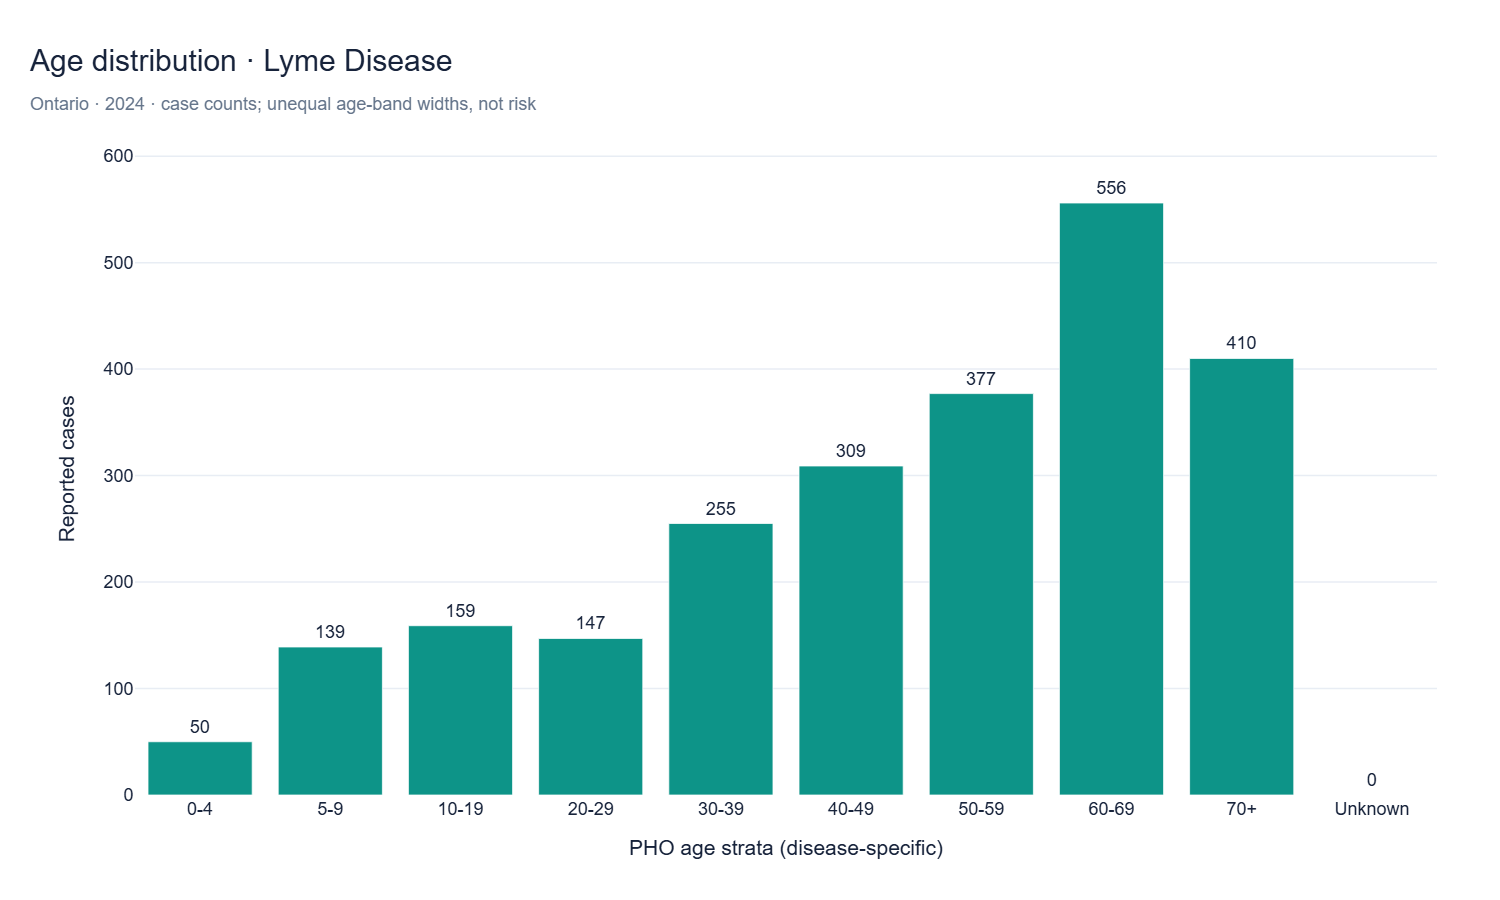

In [8]:
# ============================================================
# 07 | Chart 4 — Disease-Specific Age Distribution
# ============================================================
def age_interval(label):
    """Return inclusive numeric age bounds; return None for nonnumeric labels."""
    if pd.isna(label):
        return None
    label = str(label).strip()
    match = re.fullmatch(r"(\d+)-(\d+)", label)
    if match:
        return tuple(map(int, match.groups()))
    match = re.fullmatch(r"(\d+)\+", label)
    if match:
        return (int(match.group(1)), 125)
    if label.lower() == "neonatal":
        return (0, 0)
    return None


def overlapping_bands(labels):
    parsed = [(label, age_interval(label)) for label in labels]
    parsed = [(name, span) for name, span in parsed if span is not None]
    return [(name_a, name_b) for i, (name_a, a) in enumerate(parsed)
            for name_b, b in parsed[i+1:] if a[0] <= b[1] and b[0] <= a[1]]

age_slice = age_province.loc[
    age_province["Disease"].eq(AGE_DISEASE) & age_province["Year"].eq(REFERENCE_YEAR)
].copy()
if age_slice.empty:
    raise ValueError(f"No age data for {AGE_DISEASE} / {REFERENCE_YEAR}")

bad_pairs = overlapping_bands(age_slice["Age group"].dropna().unique())
if bad_pairs:
    raise ValueError(f"Overlapping age groups; investigate before summing: {bad_pairs[:6]}")

age_counts = (age_slice.groupby("Age group", as_index=False, dropna=False)["Number of cases"]
              .sum().rename(columns={"Number of cases": "Cases"}))
age_counts = age_counts.loc[~age_counts["Age group"].isin(["No age groups"])].copy()
age_counts["sort_age"] = age_counts["Age group"].map(
    lambda label: age_interval(label)[0] if age_interval(label) else 999)
age_counts = age_counts.sort_values(["sort_age", "Age group"])
if age_counts.empty:
    raise ValueError("No age-defined observations available for the selected disease.")

fig = px.bar(age_counts, x="Age group", y="Cases", text="Cases", color_discrete_sequence=[TEAL])
fig.update_traces(texttemplate="%{y:,.0f}", textposition="outside",
                  hovertemplate="Age stratum: %{x}<br>Cases: %{y:,.0f}<extra></extra>")
fig.update_xaxes(title="PHO age strata (disease-specific)", categoryorder="array",
                 categoryarray=age_counts["Age group"].tolist())
fig.update_yaxes(title="Reported cases", tickformat=",")
fig = finish_chart(fig, f"Age distribution · {AGE_DISEASE}",
                   f"Ontario · {REFERENCE_YEAR} · case counts; unequal age-band widths, not risk", height=535)
fig.update_layout(showlegend=False)
show_chart(fig, "04_age_distribution")

### 08 | Sex-Stratified Cases for Selected Diseases

**Question:** How do male and female **reported case counts** compare across selected diseases in 2024?  
**Metric:** unadjusted case counts, *not* sex-specific incidence or evidence of differential risk. The `Did not specify` and missing-sex records are retained in the underlying dataset but are **not** allocated to either sex. A group-by-sex comparison uses disease-specific bins, not pooled population denominators.

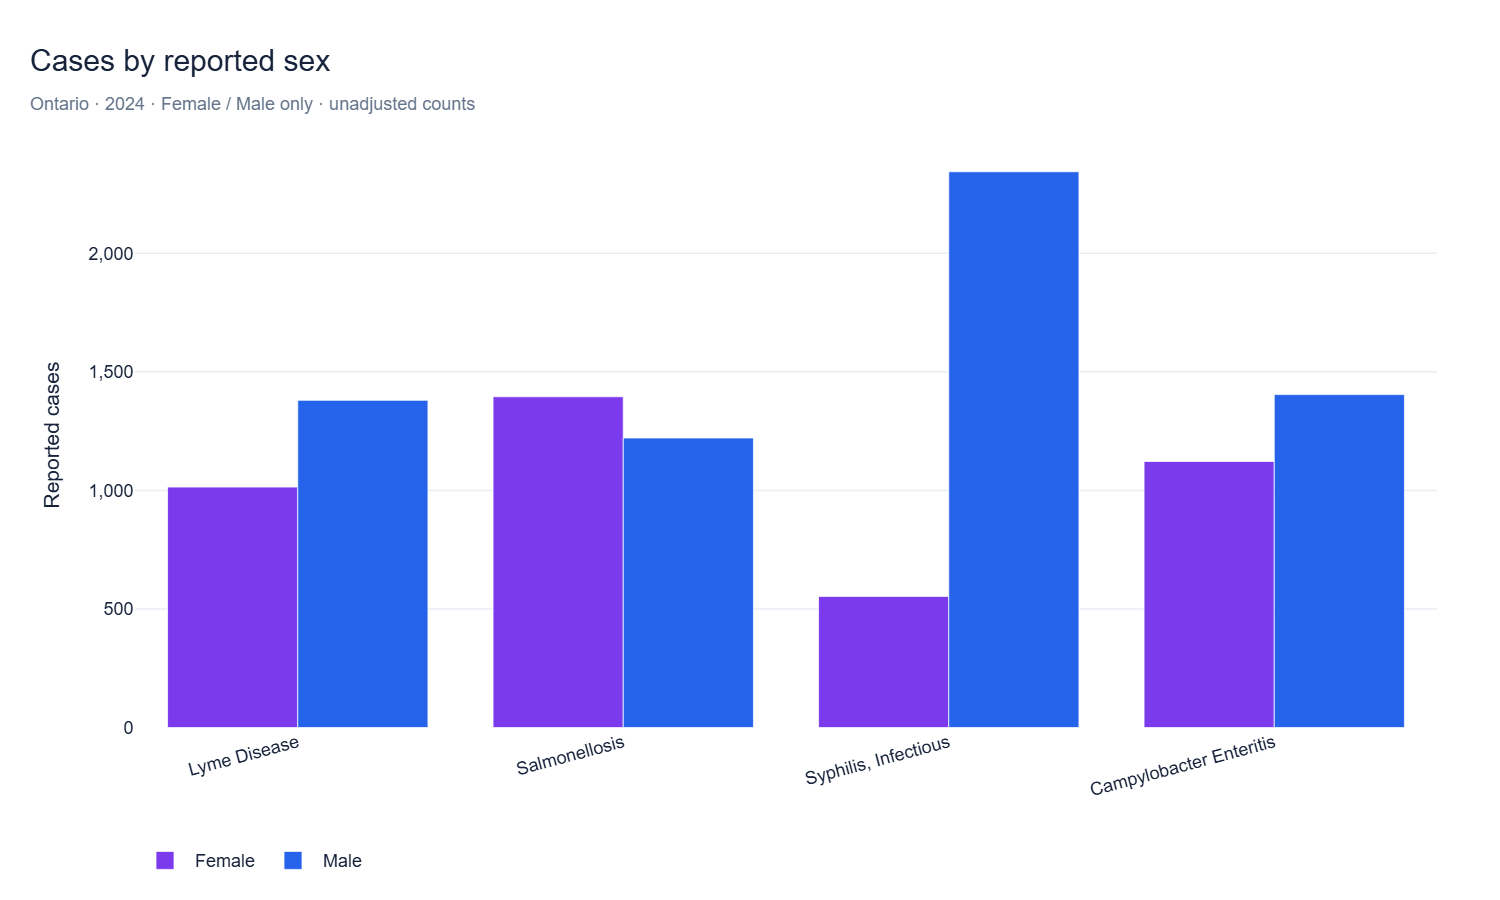

Reported cases excluded from Female/Male comparison (unknown or unspecified sex): 41


In [9]:
# ============================================================
# 08 | Chart 5 — Case Counts by Reported Sex
# ============================================================
sex_names = [d for d in SEX_DISEASES if d in age_province["Disease"].values]
if not sex_names:
    raise ValueError("None of SEX_DISEASES exist in the Age & Sex dataset.")

sex_slice = age_province.loc[
    age_province["Disease"].isin(sex_names)
    & age_province["Year"].eq(REFERENCE_YEAR)
    & age_province["Sex"].isin(["Female", "Male"])
].copy()
sex_counts = (sex_slice.groupby(["Disease", "Sex"], as_index=False)["Number of cases"]
              .sum().rename(columns={"Number of cases": "Cases"}))

fig = px.bar(sex_counts, x="Disease", y="Cases", color="Sex", barmode="group",
             category_orders={"Disease": sex_names, "Sex": ["Female", "Male"]},
             color_discrete_map={"Female": VIOLET, "Male": BLUE})
fig.update_traces(hovertemplate="%{x}<br>%{fullData.name}: %{y:,.0f} cases<extra></extra>")
fig.update_xaxes(title=None, tickangle=-15)
fig.update_yaxes(title="Reported cases", tickformat=",")
fig = finish_chart(fig, "Cases by reported sex", f"Ontario · {REFERENCE_YEAR} · Female / Male only · unadjusted counts", height=570)
show_chart(fig, "05_sex_stratified_counts")

excluded_sex_cases = age_province.loc[
    age_province["Disease"].isin(sex_names) & age_province["Year"].eq(REFERENCE_YEAR)
    & ~age_province["Sex"].isin(["Female", "Male"]), "Number of cases"
].sum()
print(f"Reported cases excluded from Female/Male comparison (unknown or unspecified sex): {excluded_sex_cases:,.0f}")

### 09 | Hospitalization & Death Outcomes

**Question:** How did the **proportion of cases with each reported outcome** evolve for a selected disease?  
**Metric:** PHO's `Percent of cases with outcome`, at the **Ontario** level. Outcome coverage is limited to diseases and outcome types available in the corresponding export; missing years/outcomes are **not** interpreted as 0%.

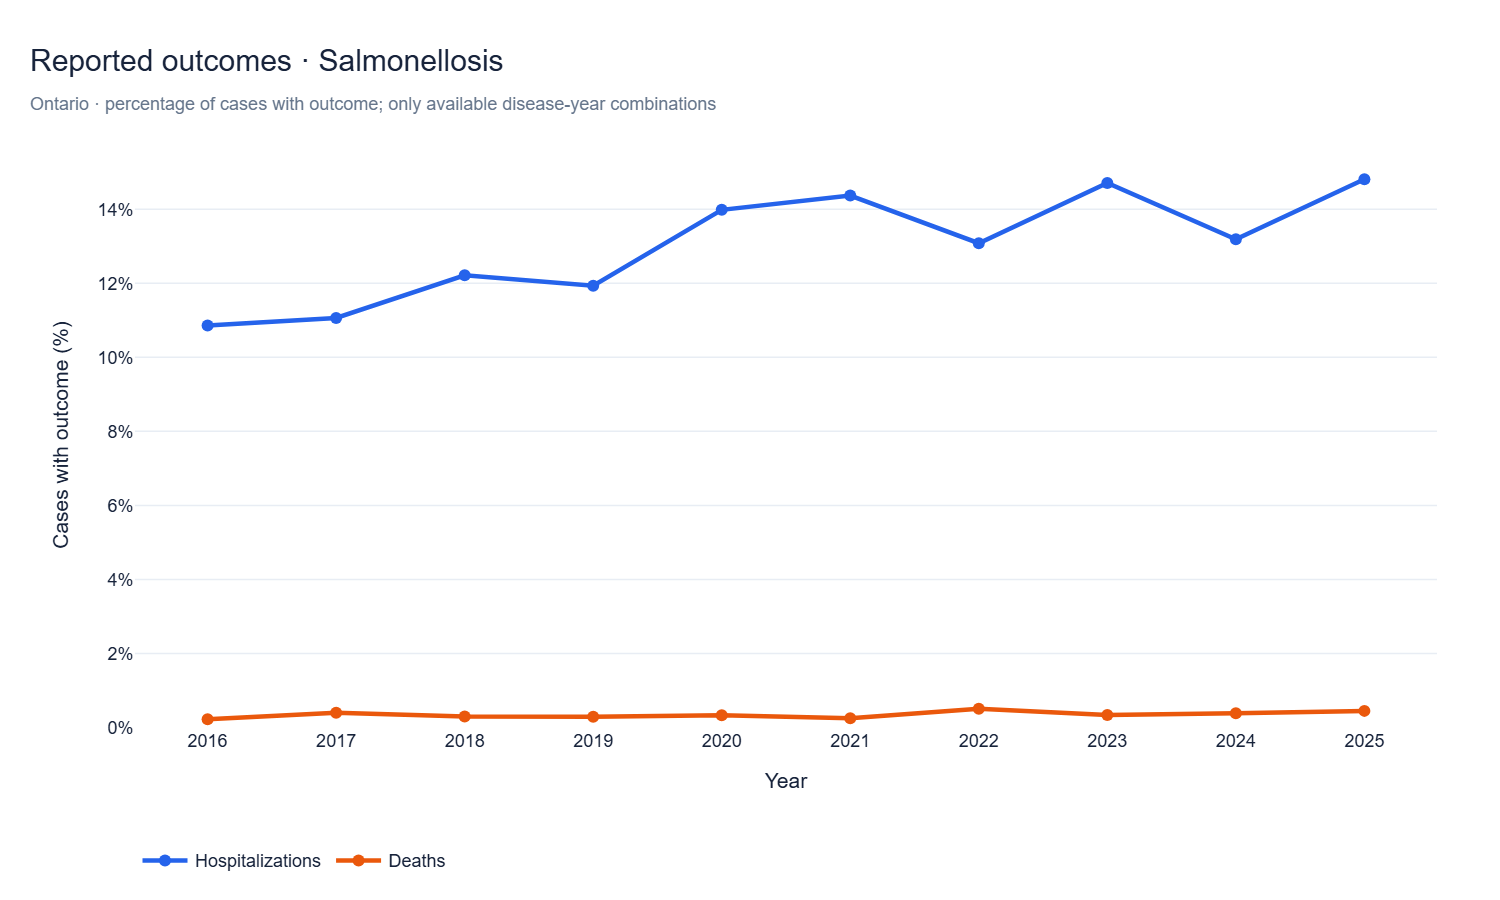

In [10]:
# ============================================================
# 09 | Chart 6 — Reported Outcome Percentages
# ============================================================
available_outcomes = outcome_province.groupby("Disease")["Outcome"].nunique()
both_outcomes = available_outcomes.loc[available_outcomes.ge(2)].index.tolist()
if not both_outcomes:
    raise ValueError("No disease has two distinct outcome types in the current export.")
chosen_outcome_disease = OUTCOME_DISEASE if OUTCOME_DISEASE in both_outcomes else both_outcomes[0]
if chosen_outcome_disease != OUTCOME_DISEASE:
    print(f"Outcome choice unavailable for both types; using: {chosen_outcome_disease}")

outcome_chart = outcome_province.loc[
    outcome_province["Disease"].eq(chosen_outcome_disease)
].sort_values("Year")
fig = px.line(
    outcome_chart, x="Year", y="Percent of cases with outcome", color="Outcome", markers=True,
    color_discrete_map={"Hospitalizations": BLUE, "Deaths": CORAL},
    category_orders={"Outcome": ["Hospitalizations", "Deaths"]},
)
fig.update_traces(line={"width": 3}, marker={"size": 8}, connectgaps=False,
                  hovertemplate="%{fullData.name}<br>%{x}: %{y:.2f}% of recorded cases<extra></extra>")
fig.update_xaxes(title="Year", dtick=1)
fig.update_yaxes(title="Cases with outcome (%)", ticksuffix="%", rangemode="tozero")
fig = finish_chart(fig, f"Reported outcomes · {chosen_outcome_disease}",
                   "Ontario · percentage of cases with outcome; only available disease-year combinations", height=520)
show_chart(fig, "06_outcome_percentages")

### 10 | Year-over-Year Changes

**Question:** Which diseases had the largest absolute changes in Ontario case counts from 2023 to 2024?  
**Metric:** 2024 cases minus 2023 cases. A **2023 baseline of at least 50 cases** avoids highlighting large percentage swings built on one or two cases.  
**Caution:** Changes in surveillance, testing, and reporting can affect observed differences; this descriptive ranking is **not** an outbreak detector or causal analysis.

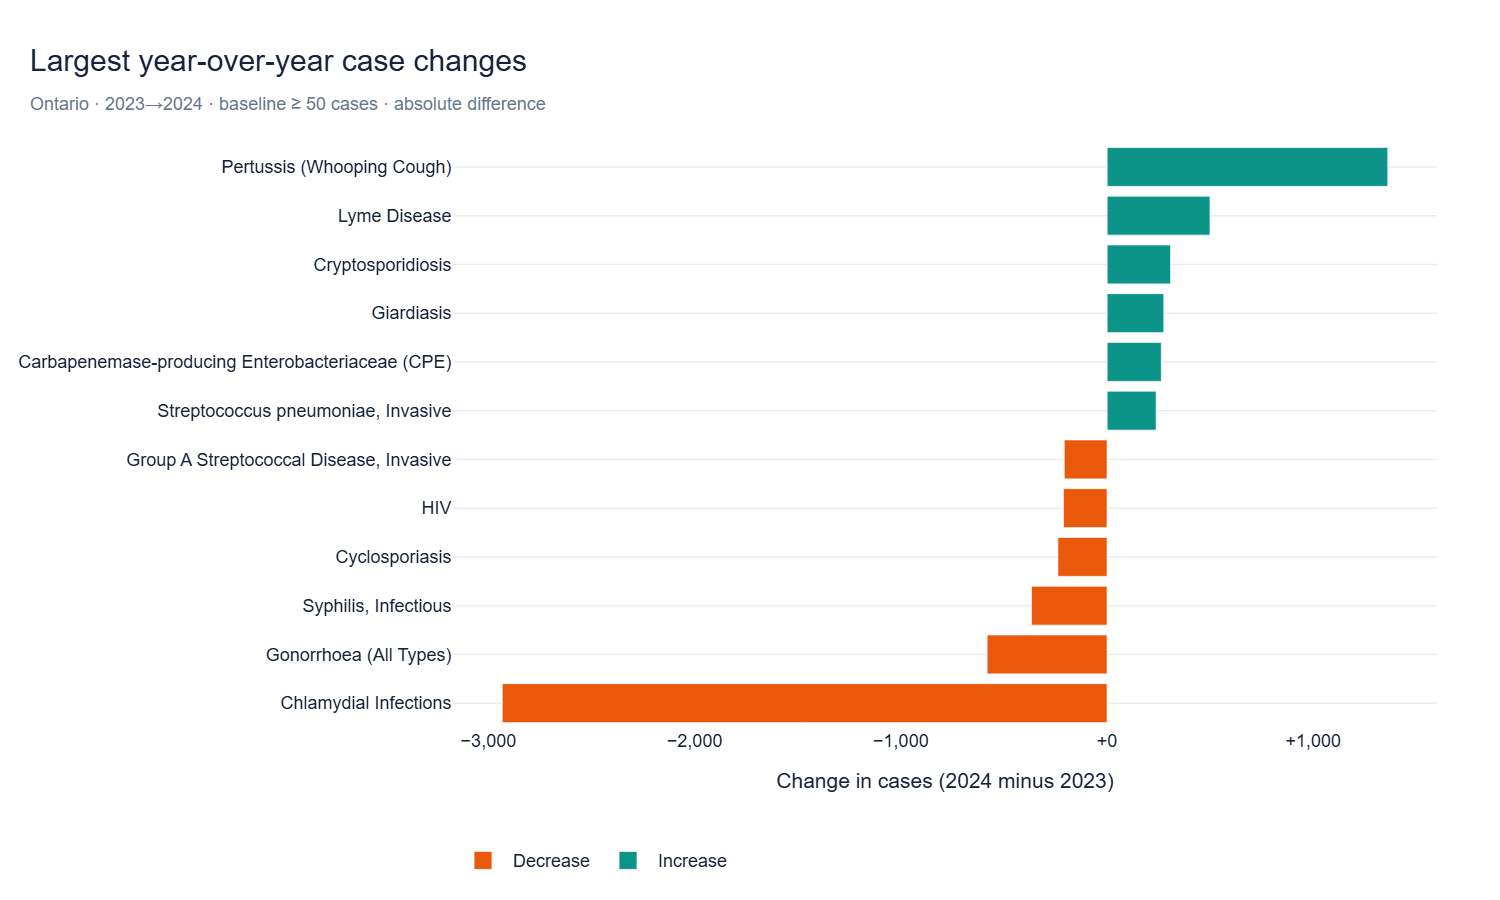

In [11]:
# ============================================================
# 10 | Chart 7 — Absolute Year-over-Year Change
# ============================================================
yoy_year = REFERENCE_YEAR
yoy_previous = REFERENCE_YEAR - 1
paired = (province_year.loc[province_year["Year"].isin([yoy_previous, yoy_year])]
          .pivot(index="Disease", columns="Year", values="Cases"))
paired = paired.dropna(subset=[yoy_previous, yoy_year])
paired = paired.loc[paired[yoy_previous].ge(MIN_BASELINE_CASES_FOR_YOY)].copy()
paired["Change"] = paired[yoy_year] - paired[yoy_previous]
paired["Percent change"] = np.where(
    paired[yoy_previous].gt(0), paired["Change"] / paired[yoy_previous] * 100, np.nan)

rising = paired.nlargest(6, "Change")
falling = paired.nsmallest(6, "Change")
changes = (pd.concat([falling, rising]).loc[lambda x: ~x.index.duplicated()]
           .reset_index().sort_values("Change"))
if changes.empty:
    raise ValueError("No eligible year-over-year comparisons found; check baseline/year.")
changes["Direction"] = np.where(changes["Change"].ge(0), "Increase", "Decrease")

fig = px.bar(changes, x="Change", y="Disease", orientation="h", color="Direction",
             color_discrete_map={"Increase": TEAL, "Decrease": CORAL},
             custom_data=["Percent change"])
fig.update_traces(hovertemplate="<b>%{y}</b><br>Change: %{x:+,.0f} cases<br>Percent change: %{customdata[0]:+.1f}%<extra></extra>")
fig.update_xaxes(title=f"Change in cases ({yoy_year} minus {yoy_previous})", tickformat="+,", zeroline=True,
                 zerolinecolor=NAVY, zerolinewidth=1)
fig.update_yaxes(title=None, categoryorder="array", categoryarray=changes["Disease"].tolist())
fig = finish_chart(fig, "Largest year-over-year case changes",
                   f"Ontario · {yoy_previous}→{yoy_year} · baseline ≥ {MIN_BASELINE_CASES_FOR_YOY} cases · absolute difference",
                   height=640, left_margin=275)
show_chart(fig, "07_year_over_year_change")

### 11 | Dashboard-Ready Data Exports

Create three independent, tidy sources for the future **Streamlit application** and **Tableau Public dashboard**. They preserve their original grains to prevent accidental duplication in BI tools.

| Export | Grain | Expected application |
|---|---|---|
| `pho_overall_tidy.csv` | Geography × disease × year | Disease trends; PHU comparisons |
| `pho_age_sex_tidy.csv` | Geography × disease × year × sex × age | Demographic views |
| `pho_outcomes_tidy.csv` | Ontario × disease × year × outcome | Outcome trends |

**Publication reminder:** Review PHO's data-source attribution and redistribution conditions before committing downloadable derived datasets to a public repository. The code/notebooks can be public independently of the input Excel files.

In [12]:
# ============================================================
# 11 | Reusable Export Tables
# ============================================================
overall_export = overall[["Public health unit", "Disease", "Year", "Cases", "Population", "Rate per 100,000"]].copy()
overall_export["Geography level"] = np.select(
    [overall_export["Public health unit"].eq("Ontario"),
     overall_export["Public health unit"].eq("Canada")],
    ["Ontario", "Canada"], default="PHU")
overall_export["Denominator available"] = overall_export["Population"].gt(0)

age_export = age[["Public health unit", "Disease", "Year", "Sex", "Age group",
                  "Number of cases", "Population", "Rate per 100,000 population"]].copy()
# Keep missing sex truly missing rather than silently assigning it to a substantive category.
outcome_export = outcome_province[["Public health unit", "Disease", "Year", "Outcome",
                                   "Cases with outcome", "Total cases", "Percent of cases with outcome"]].copy()

exports = {"pho_overall_tidy.csv": overall_export,
           "pho_age_sex_tidy.csv": age_export,
           "pho_outcomes_tidy.csv": outcome_export}
if EXPORT_DASHBOARD_TABLES:
    target = OUTPUT_DIR / "processed"
    target.mkdir(parents=True, exist_ok=True)
    for filename, table in exports.items():
        table.to_csv(target / filename, index=False)

export_summary = pd.DataFrame([
    {"Filename": filename, "Rows": len(frame), "Columns": frame.shape[1]}
    for filename, frame in exports.items()
])
display(export_summary)
print("Saved to outputs/processed/" if EXPORT_DASHBOARD_TABLES else "Exports ready in memory; file writing disabled.")

,Filename,Rows,Columns
0,pho_overall_tidy.csv,20034,8
1,pho_age_sex_tidy.csv,213741,8
2,pho_outcomes_tidy.csv,648,7


Saved to outputs/processed/


### 12 | Findings, Limitations & Next Research Steps

#### Findings to report after running
- Identify the leading reported disease **by case count** for 2024 (Chart 1).
- Describe the shape and timing of selected trends rather than assuming changes are caused by transmission alone (Chart 2).
- Use single-disease, per-100,000 PHU comparisons; do not substitute raw PHU counts for geographic risk (Chart 3).
- Summarize age and sex case distributions descriptively; population-standardized comparisons require separately validated denominators (Charts 4–5).
- Describe outcome coverage and any missing disease–year combinations (Chart 6).
- Treat 2023–2024 absolute changes as **exploratory signals** for follow-up, not as statistical anomalies (Chart 7).

#### Data and inference limitations
1. The Outcome export does not cover every disease and is Ontario-only.
2. Some rates are missing because denominators are missing or zero; charts must not encode them as 0.
3. The original quality notebook found a small number of mismatches between `Overall` and the sum of demographic strata. These have not been overwritten.
4. Disease-specific age bands and differential testing/reporting complicate comparisons.
5. Verify the status and any retrospective revisions of 2025 PHO data before describing the latest year as final.
6. The heatmap shows selected **reported surveillance rates**; no validated PHU boundary shapefile is included, so it is not a geographic choropleth.

**Next artifact:** `03_statistical_analysis.ipynb` for explicitly scoped trend estimators and anomaly screening, followed by prepared data and separate **Streamlit + Tableau** dashboards.

In [13]:
# ============================================================
# 12 | Executive Snapshot (Automatically Calculated)
# ============================================================
latest_geo = g.loc[g["Year"].eq(REFERENCE_YEAR)].dropna(subset=["Rate per 100,000"])
leading_phu = latest_geo.nlargest(1, "Rate per 100,000")
peak_increase = paired.nlargest(1, "Change")
peak_decline = paired.nsmallest(1, "Change")

findings = [
    {"Finding": "Most reported disease", "Observation": f"{top10.iloc[-1]['Disease']} · {top10.iloc[-1]['Cases']:,.0f} cases ({REFERENCE_YEAR})"},
    {"Finding": f"Highest local {GEO_DISEASE} rate", "Observation":
     (f"{leading_phu.iloc[0]['Public health unit']} · {leading_phu.iloc[0]['Rate per 100,000']:.2f}/100k ({REFERENCE_YEAR})"
      if not leading_phu.empty else "No valid local rates available")},
    {"Finding": "Largest eligible YoY increase", "Observation":
     (f"{peak_increase.index[0]} · +{peak_increase.iloc[0]['Change']:,.0f} cases"
      if not peak_increase.empty else "Not available")},
    {"Finding": "Largest eligible YoY decrease", "Observation":
     (f"{peak_decline.index[0]} · {peak_decline.iloc[0]['Change']:+,.0f} cases"
      if not peak_decline.empty else "Not available")},
    {"Finding": f"{chosen_outcome_disease} outcome coverage", "Observation":
     f"{outcome_chart['Year'].nunique()} years · {outcome_chart['Outcome'].nunique()} outcome types"},
]
display(pd.DataFrame(findings))
print("Interpret as descriptive PHO surveillance findings; review definitions and missingness before inference.")

,Finding,Observation
0,Most reported disease,"Chlamydial Infections · 42,824 cases (2024)"
1,Highest local Lyme Disease rate,Southeast Public Health · 120.60/100k (2024)
2,Largest eligible YoY increase,"Pertussis (Whooping Cough) · +1,361 cases"
3,Largest eligible YoY decrease,"Chlamydial Infections · -2,933 cases"
4,Salmonellosis outcome coverage,10 years · 2 outcome types


Interpret as descriptive PHO surveillance findings; review definitions and missingness before inference.
